In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Model
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, roc_auc_score


In [2]:
df = pd.read_csv('heart_disease_prediction_cleaned.csv')
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0



## LABEL ENCODER

In [3]:
numeric_cols = ['Age','RestingBP','Cholesterol','MaxHR','Oldpeak']
categorical_cols = ['Sex','ChestPainType','FastingBS','RestingECG', 'ExerciseAngina', 'ST_Slope']


In [4]:
le = LabelEncoder()
for col in categorical_cols:
    df[f'{col}_encoded']= le.fit_transform(df[col])
df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease', 'Sex_encoded', 'ChestPainType_encoded',
       'FastingBS_encoded', 'RestingECG_encoded', 'ExerciseAngina_encoded',
       'ST_Slope_encoded'],
      dtype='str')

## FEATURE AND TARGET

In [5]:
feature = ['Age', 'Sex_encoded', 'ChestPainType_encoded', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG_encoded', 'MaxHR', 'ExerciseAngina_encoded', 'Oldpeak', 'ST_Slope_encoded']
target = 'HeartDisease'

In [6]:
X =df[feature]
y= df[target]

## TRAIN TEST SPLIT

In [7]:
X_train, X_test, y_train, y_test = train_test_split( X ,y, random_state =42, test_size=0.2,  stratify=y)


## FEATURE SCALING

In [8]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## MODEL


In [9]:
model = LogisticRegression(
    solver = 'lbfgs',
    class_weight='balanced',
    random_state=42
)

In [10]:
model.fit(X_train_scaled, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default

In [11]:
y_pred = model.predict(X_test_scaled)


## METRICS

In [12]:
cm = confusion_matrix(y_test,y_pred)
cr = classification_report(y_test,y_pred)


In [13]:
print('Confustion Matrix')
print('---------------')
print(cm)

Confustion Matrix
---------------
[[67 15]
 [13 89]]


In [14]:
print('Classification Report')
print('------------------')
print(cr)

Classification Report
------------------
              precision    recall  f1-score   support

           0       0.84      0.82      0.83        82
           1       0.86      0.87      0.86       102

    accuracy                           0.85       184
   macro avg       0.85      0.84      0.85       184
weighted avg       0.85      0.85      0.85       184



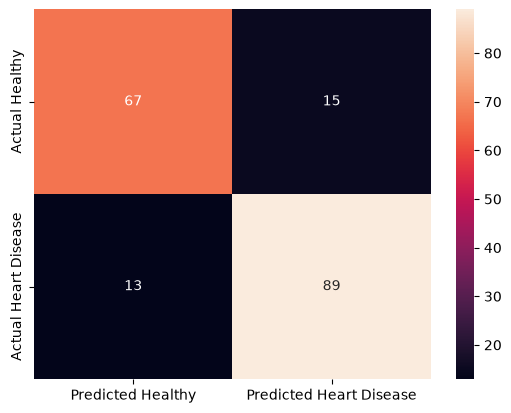

In [15]:
sns.heatmap(cm, annot=True, fmt='1.0f', xticklabels=['Predicted Healthy','Predicted Heart Disease'], yticklabels=['Actual Healthy', 'Actual Heart Disease'])
plt.show()

## TUNING THRESHOLD

In [16]:
y_prob = model.predict_proba(X_test_scaled)[:,-1] #unhealthy columns

In [17]:

roc_curve(y_test, y_prob)

(array([0.        , 0.        , 0.        , 0.01219512, 0.01219512,
        0.02439024, 0.02439024, 0.03658537, 0.03658537, 0.06097561,
        0.06097561, 0.07317073, 0.07317073, 0.08536585, 0.08536585,
        0.09756098, 0.09756098, 0.1097561 , 0.1097561 , 0.14634146,
        0.14634146, 0.15853659, 0.15853659, 0.18292683, 0.18292683,
        0.19512195, 0.19512195, 0.24390244, 0.24390244, 0.2804878 ,
        0.2804878 , 0.3902439 , 0.3902439 , 0.47560976, 0.47560976,
        0.6097561 , 0.6097561 , 0.68292683, 0.68292683, 0.85365854,
        0.85365854, 1.        ]),
 array([0.        , 0.00980392, 0.07843137, 0.07843137, 0.14705882,
        0.14705882, 0.37254902, 0.37254902, 0.44117647, 0.44117647,
        0.51960784, 0.51960784, 0.61764706, 0.61764706, 0.69607843,
        0.69607843, 0.82352941, 0.82352941, 0.84313725, 0.84313725,
        0.85294118, 0.85294118, 0.87254902, 0.87254902, 0.89215686,
        0.89215686, 0.90196078, 0.90196078, 0.93137255, 0.93137255,
        0.9509

In [25]:
fpr, tpr, threshold = roc_curve(y_test, y_prob)
auc= roc_auc_score(y_test, y_prob)
auc

0.9056671449067432

In [19]:
j_scores = tpr- fpr
best_idx = np.argmax(j_scores)
best_tpr = tpr[best_idx]
best_fpr = fpr[best_idx]
best_threshold= threshold[best_idx]


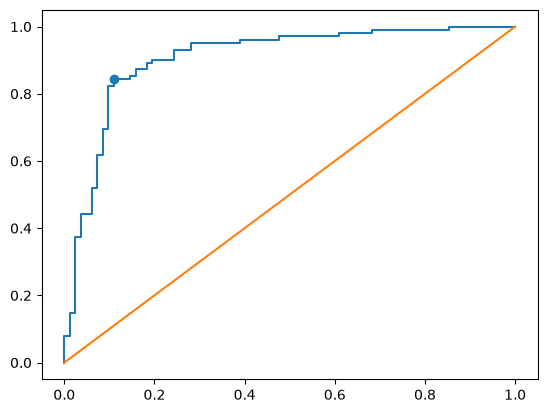

In [26]:
plt.plot(fpr, tpr)
plt.scatter(best_fpr, best_tpr)
plt.plot([0,1],[0,1])

In [30]:
y_prob_opt = (y_prob >= best_threshold).astype(int)
y_prob_opt

array([0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0,
       1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1,
       1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1,
       0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0,
       0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0,
       0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0,
       0, 0, 1, 0, 1, 1, 1, 1])

In [31]:
new_cm = confusion_matrix(y_test, y_prob_opt)
new_cr = classification_report(y_test, y_prob_opt)

In [32]:
new_cm

array([[73,  9],
       [16, 86]])

In [34]:
print(new_cr)

              precision    recall  f1-score   support

           0       0.82      0.89      0.85        82
           1       0.91      0.84      0.87       102

    accuracy                           0.86       184
   macro avg       0.86      0.87      0.86       184
weighted avg       0.87      0.86      0.86       184

